# Exercise 15 – Global optimisation: random starts and particle swarms

**Week 3 · Monte Carlo and optimisation of clusters**

A local optimiser only finds the nearest minimum. Two simple global
strategies:

1. **Random restarts** – relax many random starting configurations and
   compare the resulting energies.
2. **Particle swarm optimisation (PSO)** – a set of "particles" explores the
   search space; each is pulled towards its own best position so far and
   towards the best position found by the whole swarm.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.atoms import Cluster, LennardJones, line_search_relax, random_positions

rng = np.random.default_rng(0)
calc = LennardJones()

## Random restarts
$n$ mobile atoms placed randomly around a fixed atom (orange), each relaxed
with the line-search optimiser of exercise 14. Panels are sorted by energy.

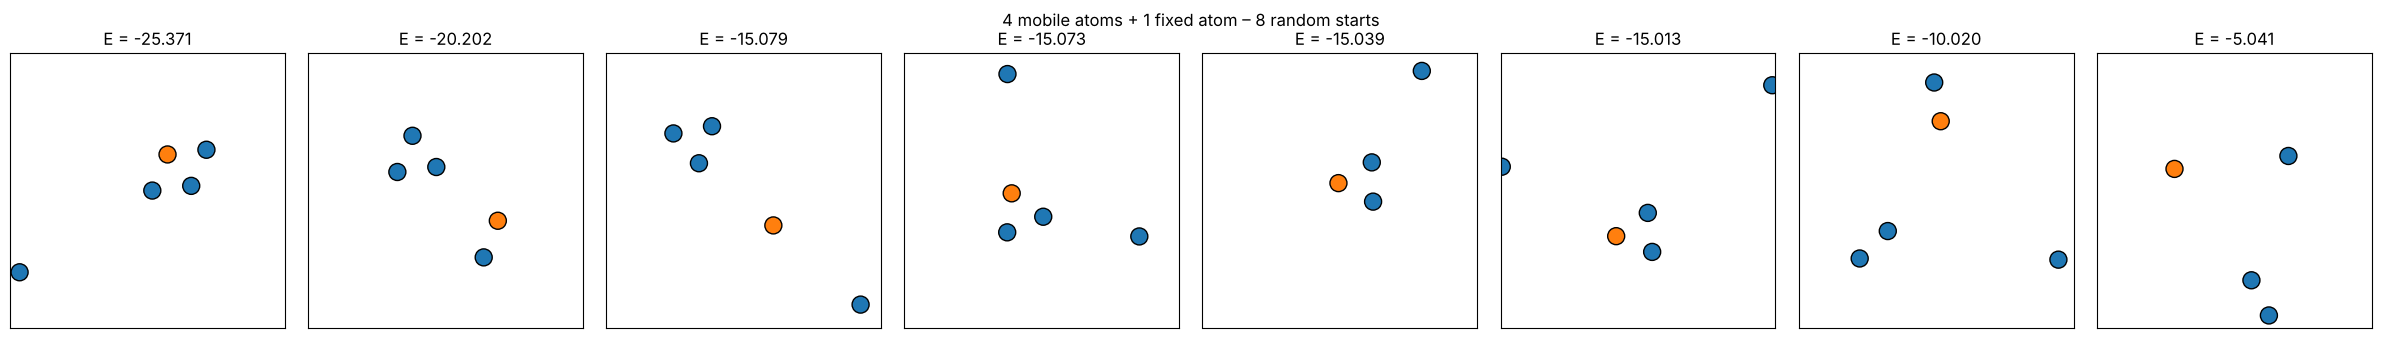

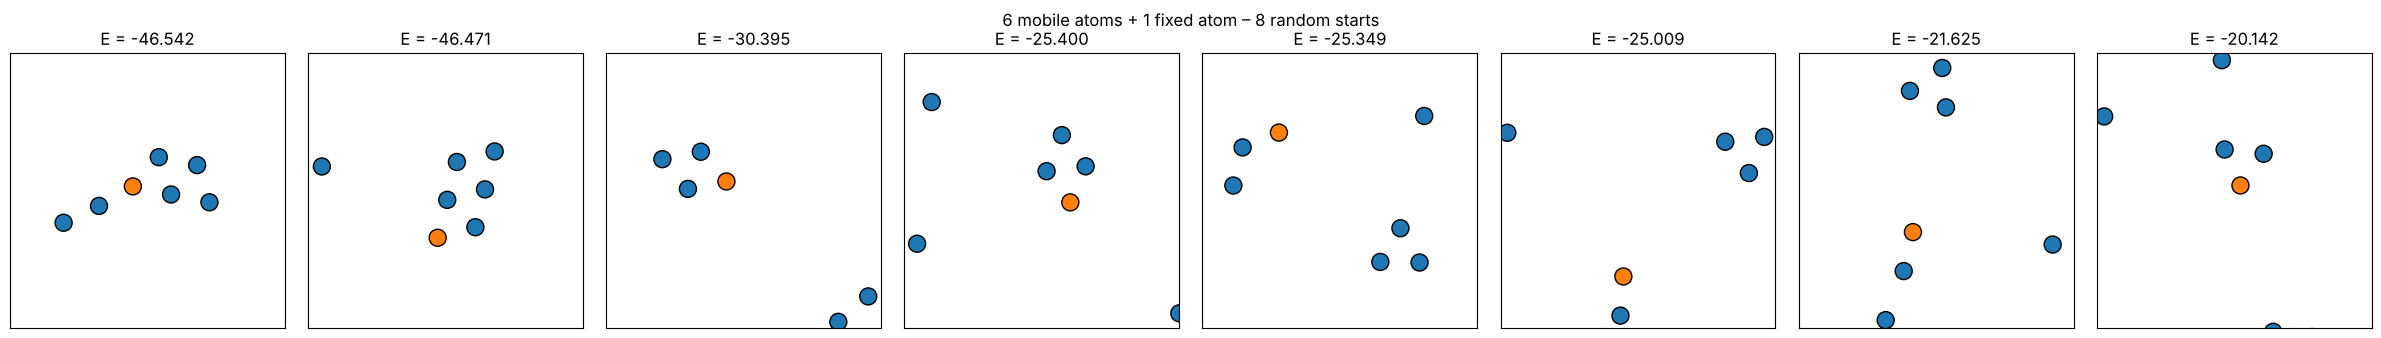

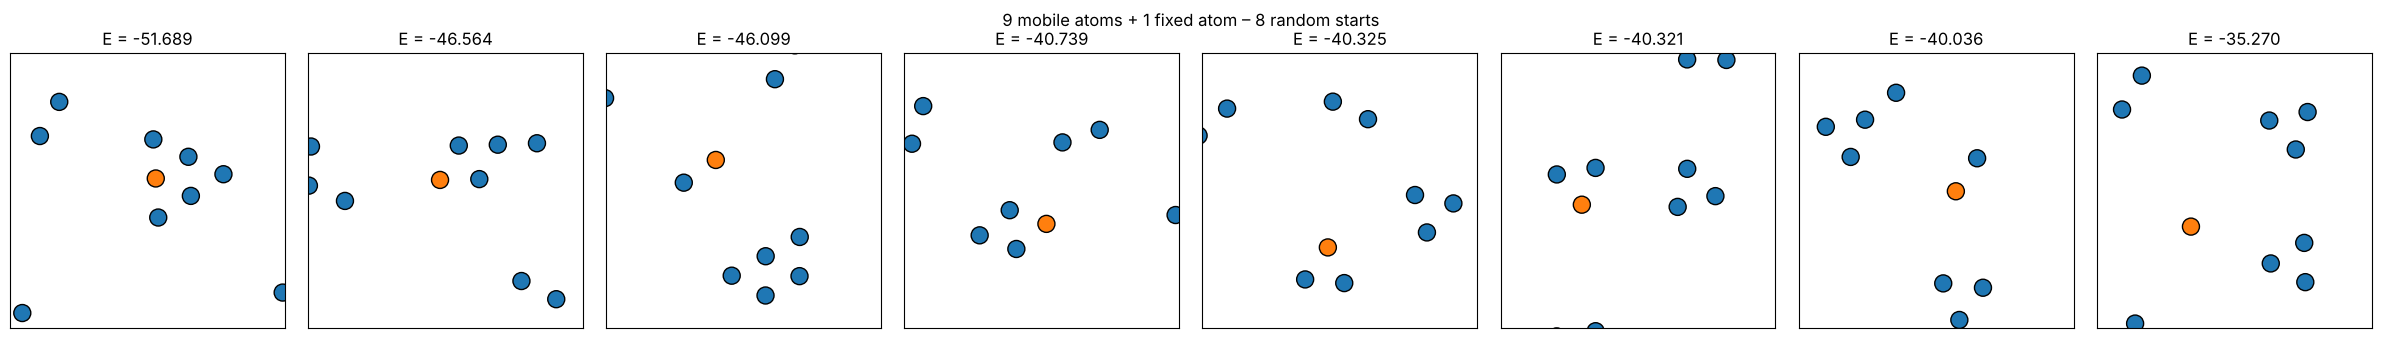

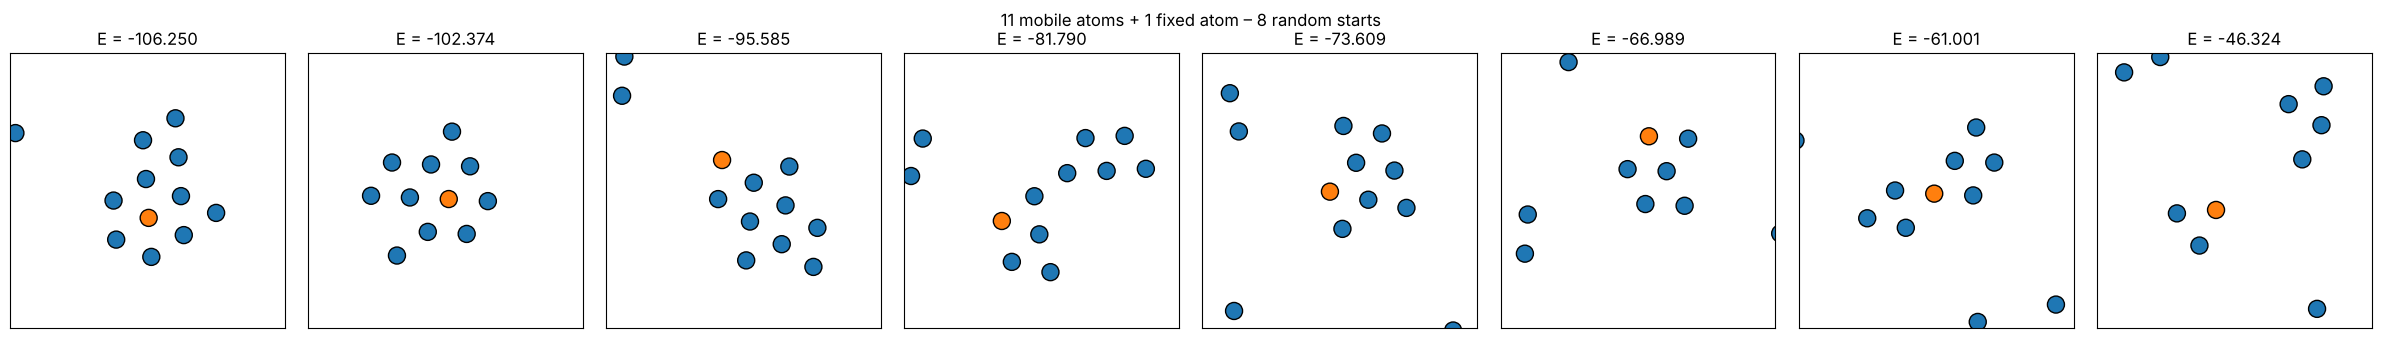

In [2]:
for n in [4, 6, 9, 11]:
    clusters = []
    for _ in range(8):
        start = np.vstack([random_positions(n, 4, min_distance=0.5, rng=rng), [[0, 0]]])
        cluster = Cluster(calc, start, static=[False] * n + [True])
        line_search_relax(cluster, max_steps=1000)
        clusters.append(cluster)
    clusters.sort(key=lambda c: c.energy)

    fig, axes = plt.subplots(1, 8, figsize=(24, 3.4))
    for ax, c in zip(axes, clusters):
        c.draw(ax, size=150)
        centre = c.positions.mean(axis=0)
        ax.set(xlim=(centre[0] - 3.5, centre[0] + 3.5), ylim=(centre[1] - 3.5, centre[1] + 3.5),
               xticks=[], yticks=[])
    fig.suptitle(f"{n} mobile atoms + 1 fixed atom – 8 random starts")
    fig.tight_layout()
    plt.show()

Small clusters usually reach the compact triangular arrangement; with more
atoms the relaxed structures differ from start to start, showing how the
number of local minima grows with system size.

## Particle swarm optimisation
Where should a third atom go next to two fixed atoms at $(\pm1, 0)$? Each
swarm particle is a candidate position $\mathbf p$ for the atom, with
velocity update

$$\mathbf v \leftarrow w\mathbf v + c_1 r_1(\mathbf p_\text{best} - \mathbf p)
  + c_2 r_2(\mathbf g_\text{best} - \mathbf p), \qquad r_1, r_2 \sim U(0,1).$$

In [3]:
fixed = np.array([[-1.0, 0.0], [1.0, 0.0]])


def energy_of(p):
    return calc.energy(np.vstack([fixed, p]))


def particle_swarm(f, n_particles=20, bounds=(-3, 3), iterations=200, w=0.5, c1=1.5, c2=1.5,
                   rng=None):
    rng = np.random.default_rng(rng)
    x = rng.uniform(*bounds, (n_particles, 2))
    v = rng.uniform(-1, 1, (n_particles, 2))
    p_best, p_val = x.copy(), np.array([f(p) for p in x])
    g_best = p_best[p_val.argmin()].copy()
    history = [x.copy()]
    for _ in range(iterations):
        r1, r2 = rng.random((2, n_particles, 1))
        v = w * v + c1 * r1 * (p_best - x) + c2 * r2 * (g_best - x)
        x = np.clip(x + v, *bounds)
        vals = np.array([f(p) for p in x])
        better = vals < p_val
        p_best[better], p_val[better] = x[better], vals[better]
        g_best = p_best[p_val.argmin()].copy()
        history.append(x.copy())
    return g_best, p_val.min(), np.array(history)


best, e_best, history = particle_swarm(energy_of, rng=rng)
print(f"best position {best.round(4)}, energy {e_best:.4f} "
      f"(exact minimum: (0, 0) with E = {energy_of([0, 0]):.4f})")

best position [0. 0.], energy -10.1550 (exact minimum: (0, 0) with E = -10.1550)


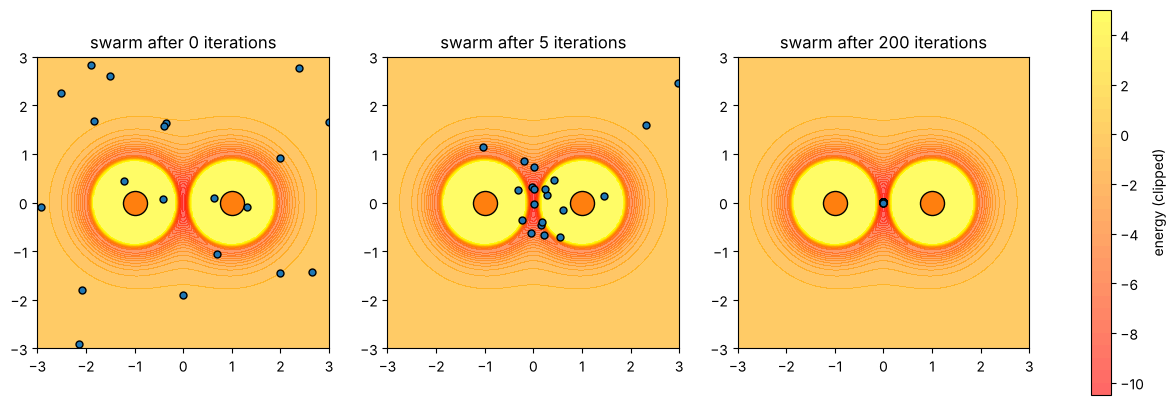

In [4]:
xs = np.linspace(-3, 3, 200)
Z = np.array([[energy_of([x, y]) for x in xs] for y in xs])
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, it in zip(axes, [0, 5, 200]):
    filled = ax.contourf(xs, xs, np.clip(Z, -11, 5), levels=30, cmap="autumn", alpha=0.6)
    ax.scatter(*fixed.T, s=300, c="C1", edgecolor="black")
    ax.scatter(*history[it].T, s=25, c="C0", edgecolor="black")
    ax.set(aspect="equal", title=f"swarm after {it} iterations", xlim=(-3, 3), ylim=(-3, 3))
fig.colorbar(filled, ax=axes, label="energy (clipped)")
plt.show()

The fixed atoms are 2 apart, so the point midway between them is at the
optimal bond length (1) from both – the swarm converges there.